# GP2 Bioinformatics Training Workshop Argentina  

## Whole-Genome Data Analysis - Homozygosity (ROH)

<span style="background-color: #90EE90">GP2 ❤️ Open Science 😍</span>

**Module:** Homozygosity / Runs of Homozygosity (ROH)

**Author:** Carlos Hernández and Zih-Hua Fang on behalf of the Global Parkinson's Genetics Program (ASAP)

**Estimated Computation and Runtime:**

**Estimated Specifications:** Default; 4 CPU, 15 GB Memory, 50 GB Persistent Disk Size  
**Estimated Runtime:** 30 min.  
**Date Last Updated:** 24/07/2026

## Notebook Summary

##### 2. [Getting Started](##2)
This section goes through:

- Set up environment
- Install PLINK1.9 / PLINK2 (https://www.cog-genomics.org/plink/)
- Prepare inputs required for ROH calling to workspace

##### 3. [Run ROH calling and calculate FROH](##2)
This section goes through:

- QC/MAF-filter raw genotypes with PLINK2
- Call ROH segments with PLINK1.9 `--homozyg`
- Calculate per-sample FROH from `.hom`

##### 4. [Extract consensus ROH regions and WGS variants](##2)
This section goes through:

- Identify consensus/pooled ROH regions from `.hom.overlap`
- Build BED intervals per pool
- Extract WGS variants within those regions for samples with paired NBA+WGS data

##### 5. [Visualize genotypes within ROH regions](##2)
This section goes through:

- Build per-pool genotype heatmaps (hom ref / het / hom alt) to visually confirm
  homozygosity patterns

## Getting Started 

### Set up environment

In [ ]:
# Use the os package to interact with the environment
import os

# Bring in Pandas for Dataframe functionality
import pandas as pd

# Numpy for basics
import numpy as np

# Use StringIO for working with file contents
from io import StringIO

# Enable IPython to display matplotlib graphs
import matplotlib.pyplot as plt
%matplotlib inline

# Import Sys
import sys as sys

import pathlib
from pathlib import Path

import glob
import subprocess
import seaborn as sns

### Install PLINK1.9 and PLINK2

In [ ]:
# Point mamba/conda to a package cache the current user owns
os.environ["CONDA_PKGS_DIRS"] = os.path.expanduser("~/.conda/pkgs")

In [ ]:
! mamba install  -c bioconda -c conda-forge plink plink2 -y

## Define Paths

In [ ]:
## Define GP2 Release 12 paths
#These paths point to the shared GP2 Release 12 data. They are not changed by the trainee working directory.
#GP2 data paths may change between releases. Confirm the paths before rerunning an older notebook.
   
## GP2 v12.0
## Explicitly define release v12.0 path 
REL12_PATH                  = pathlib.Path(pathlib.Path.home(), 'workspace/gp2_tier2_eu_release12')
WGS_DATA_PATH               = pathlib.Path(REL12_PATH, 'wgs/dragen_joint_calling/plink')
WGS_RELATED_PATH            = pathlib.Path(REL12_PATH, 'wgs/dragen_joint_calling/related_samples')
CLINICAL_DATA_PATH          = pathlib.Path(REL12_PATH, 'clinical_data/master_key_release12_final_vwb.csv')
PCS_GENO_PATH               = pathlib.Path(REL12_PATH, 'wgs/dragen_joint_calling/pcs/')
EXTENDED_CLINICAL_DATA_PATH = pathlib.Path(REL12_PATH, 'clinical_data/r12_extended_clinical_data_vwb.csv')
RELATED_DATA_PATH           = pathlib.Path(REL12_PATH, 'meta_data/related_samples/')
RAW_GENO_PATH               = pathlib.Path(REL12_PATH, 'raw_genotypes')
RAW_FLIPPED_PATH            = pathlib.Path(REL12_PATH, 'raw_genotypes_flipped')
IMPUTED_GENO_PATH           = pathlib.Path(REL12_PATH, 'imputed_genotypes')

print("Release path:", REL12_PATH)
print("PC path:", PCS_GENO_PATH)
print(PCS_GENO_PATH.exists())

In [ ]:
## GP2 v12.0

# Display the available files in the clinical_data and meta_data directories.

!ls -hal {REL12_PATH}/clinical_data
!ls -hal {REL12_PATH}/meta_data

## Add your name and create a directory for your analysis

In [ ]:
traineeID = "your_name"
WORK_DIR = f"/home/jupyter/workspace/ws_files/INTERMEDIATE_LEVEL_WORKSHOP/Homozygosity_{traineeID}"
! mkdir -p {WORK_DIR}

In [ ]:
os.chdir(WORK_DIR)

## Homozygosity / Runs of Homozygosity (ROH) — Overview

### Definition

A **Run of Homozygosity (ROH)** is a contiguous stretch of the genome where an 
individual is homozygous at every genotyped marker — inherited identically 
from both parents. Long ROH segments typically indicate parental relatedness 
(consanguinity) or reduced population diversity, and are a proxy for genomic 
inbreeding.

**FROH** (the inbreeding coefficient estimated from ROH) is calculated as the 
fraction of the autosomal genome covered by ROH segments above a length 
threshold, relative to total genome length.

## Why it matters for PD/AD genetics

- Regions of extended homozygosity can harbor **recessive pathogenic variants** 
  (relevant for genes like PRKN, which is typically recessive)
- High FROH individuals/families are candidates for **recessive disease gene 
  discovery** — pathogenic variants are more likely to surface as homozygous 
  in these regions
- Consensus ROH regions shared across a **family or pool of related samples** 
  can be intersected with WGS data to prioritize candidate causal variants

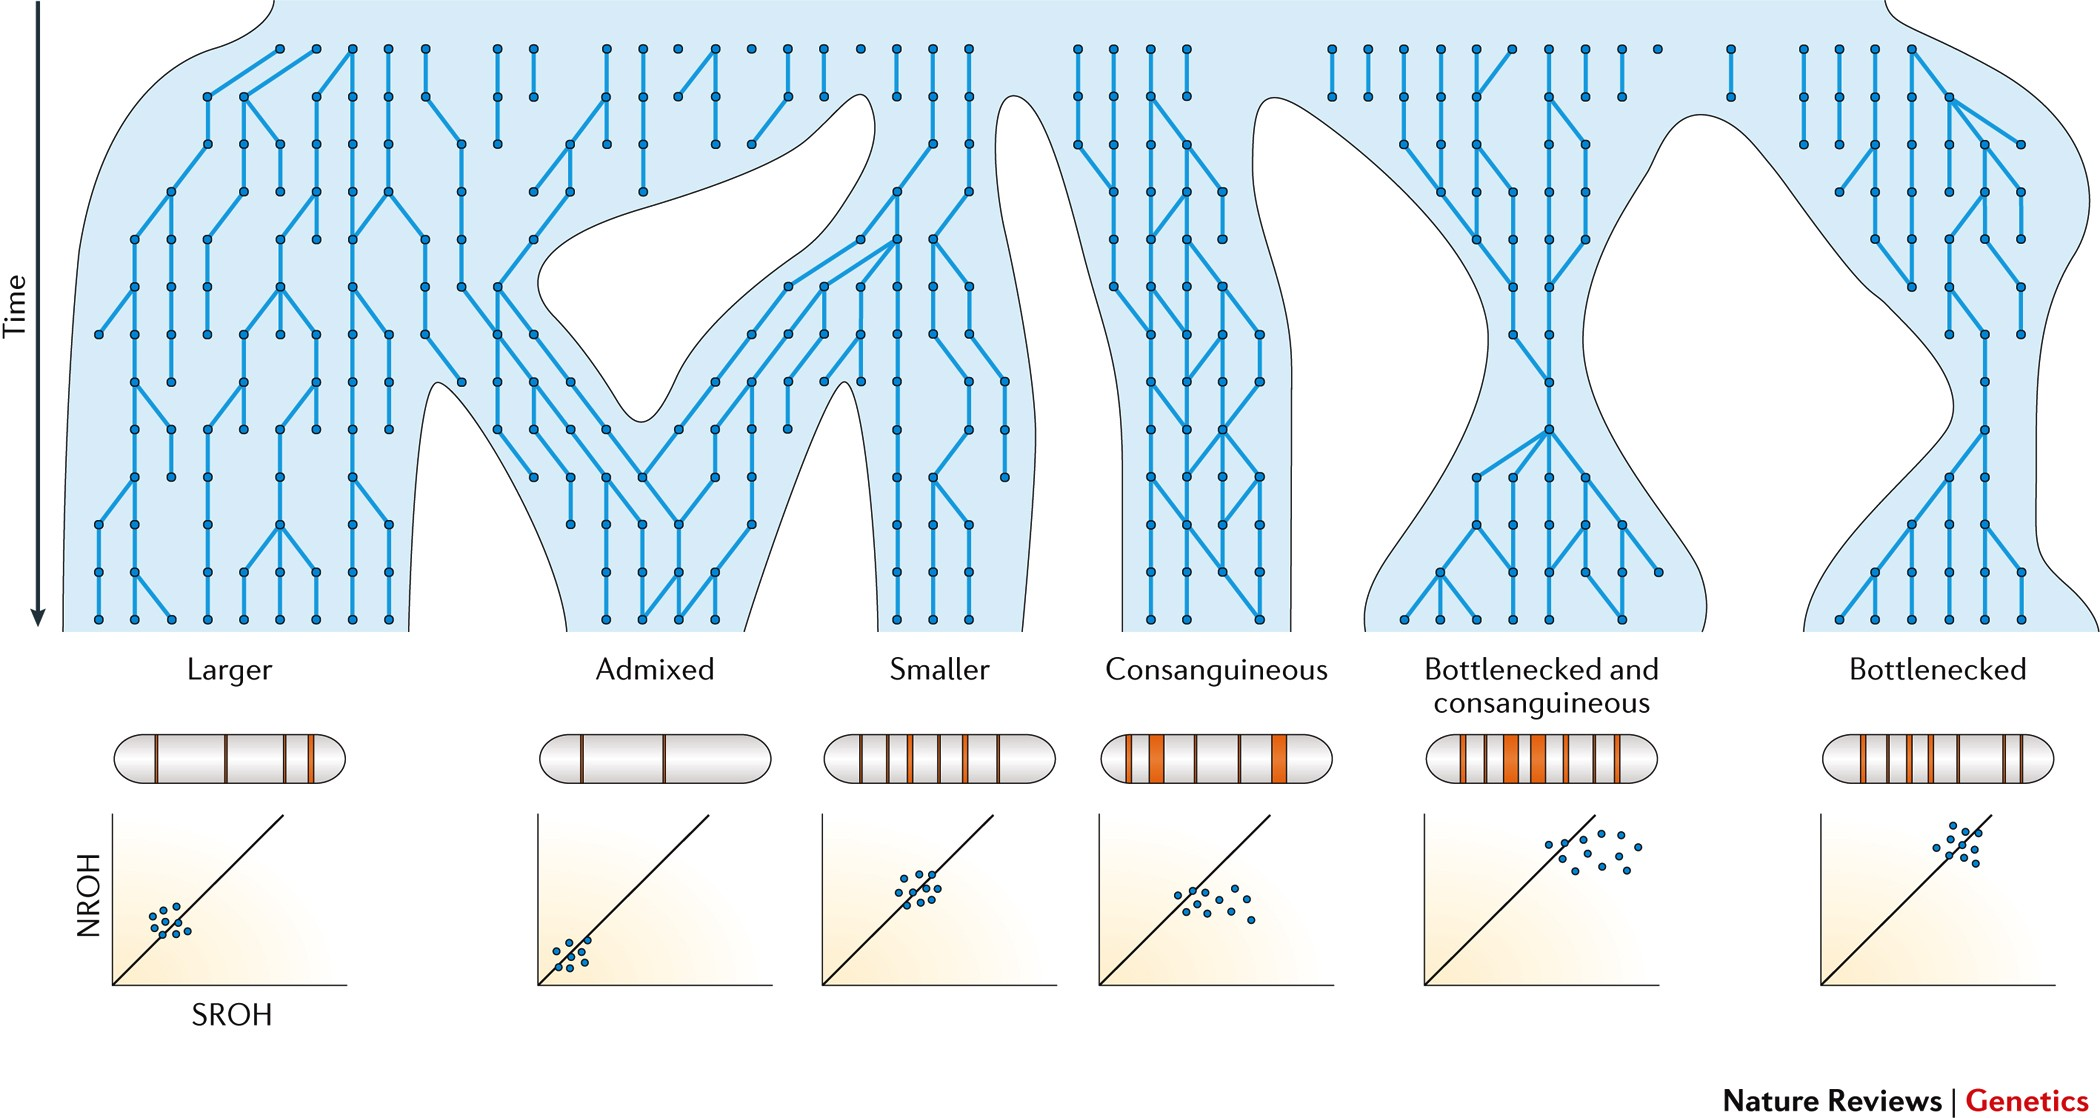

## Workflow

1. **QC + MAF filter:** PLINK2 on flipped raw genotypes, MAF ≥ 0.05 → clean 
   bed/bim/fam set
2. **ROH calling:** PLINK1.9 `--homozyg` (params: `--homozyg-snp 50`, 
   `--homozyg-kb 1500`) → `.hom` (per-segment) and `.hom.overlap` (pooled/ 
   consensus regions across samples)
3. **FROH calculation:** sum ROH segment lengths (`KB` column) per individual 
   from `.hom`, divide by total autosomal length (genome build-specific 
   denominator) → per-sample FROH table
4. **Pool/consensus extraction:** from `.hom.overlap`, identify shared ROH 
   regions (`POOL`, `UNION` rows) across related samples → build BED intervals 
   per pool
5. **WGS variant extraction:** for samples with paired NBA + WGS data, extract 
   variants falling inside consensus ROH BED regions using PLINK2 
   (`--extract bed1`, `--keep <pool>_samples.txt`) → per-pool VCF
6. **Visualization:** genotype heatmaps per pool (0 = hom ref, 1 = het, 
   2 = hom alt) across the ROH region, to visually confirm the homozygosity 
   pattern and inspect variant-level detail within the shared segment

**Flow:** 
`Raw genotypes → QC/MAF filter → PLINK homozyg → .hom (FROH) + .hom.overlap (consensus regions) → BED intervals per pool → WGS variant extraction → genotype heatmap`

## Run ROH calling and calculate FROH

### QC and MAF filter

In [ ]:
ANC='AMR'

In [ ]:
%%bash -s {RAW_FLIPPED_PATH} {WORK_DIR} {ANC}
RAW_FLIPPED_PATH=$1
WORK_DIR=$2
ANC=$3
plink2 \
    --pfile ${RAW_FLIPPED_PATH}/${ANC}/${ANC}_release12_flipped_vwb \
    --maf 0.05 \
    --make-bed \
    --out ${WORK_DIR}/${ANC}_QC \
    --memory 12000

## Call ROH segments with PLINK1.9

In [ ]:
%%bash -s {WORK_DIR} {ANC}
WORK_DIR=$1
ANC=$2
plink \
    --bfile ${WORK_DIR}/${ANC}_QC \
    --homozyg group \
    --homozyg-density 50 \
    --homozyg-gap 1000 \
    --homozyg-kb 1500 \
    --homozyg-snp 100 \
    --homozyg-window-het 1 \
    --homozyg-window-missing 5 \
    --homozyg-window-snp 50 \
    --homozyg-window-threshold 0.05 \
    --homozyg-match 0.95 \
    --out ${WORK_DIR}/ROH_${ANC}_QC

## Calculate per-sample FROH

FROH = sum of ROH segment lengths (KB) for the individual, divided by the
total autosomal length covered by the marker set.

In [ ]:
%%bash -s {WORK_DIR} {ANC}
WORK_DIR=$1
ANC=$2
GENOME_KB=2886428

(echo -e "IID\tFROH"; awk -v denom="$GENOME_KB" \
    'NR > 1 {roh[$2] += $10} END {for (id in roh) printf "%s\t%.6f\n", id, roh[id]/denom}' \
    ${WORK_DIR}/ROH_${ANC}_QC.hom) > ${WORK_DIR}/FROH_${ANC}.txt


In [ ]:
# Load FROH results into a dataframe for downstream filtering/plotting
froh_df = pd.read_csv(f"{WORK_DIR}/FROH_{ANC}.txt", sep="\t")
froh_df.sort_values("FROH", ascending=False).head(10)

# Extract consensus ROH regions and WGS variants

## Read pool overlap file

`.hom.overlap` contains pooled/consensus regions where ROH segments overlap
across multiple related individuals. `UNION` rows give the outer boundary of
the overlapping region for a pool.

In [ ]:
roh = pd.read_csv(f"{WORK_DIR}/ROH_{ANC}_QC.hom.overlap", sep=r"\s+")
roh

In [ ]:
roh_con = roh[roh['FID'] == 'CON']
roh_con

In [ ]:
roh_con_cases = roh_con[roh_con['PHE'].str.contains(':0')]
roh_con_cases

In [ ]:
roh_con_cases_all = roh[roh['POOL'].isin(roh_con_cases['POOL'].tolist())]
roh_con_cases_all

In [ ]:
# Filter out CON/UNION rows (they don't have a real GRP value, GRP is NaN)
roh_matches = roh_con_cases_all[roh_con_cases_all['GRP'].notna()].copy()

# Strip the asterisk so the reference ('1*') and its matches ('1') are treated
# as the same group — '1*' is just the reference sample within group '1'
roh_matches['GRP_BASE'] = roh_matches['GRP'].astype(str).str.replace('*', '', regex=False)

# Group by POOL and GRP_BASE to count how many IID share the same allele match
group_counts = (
    roh_matches
    .groupby(['POOL', 'GRP_BASE'])['IID']
    .agg(n_shared='count', iids=lambda x: list(x))
    .reset_index()
)

# Keep only groups where more than 1 individual shares the same alleles
shared_alleles = group_counts[group_counts['n_shared'] > 1]
print(shared_alleles)

In [ ]:
# Define which pools (families/sample groups) to extract
pools_to_extract = ['S8417','S8477','S8626','S8627','S8722'] 

In [ ]:
# Build a lookup of shared IIDs per pool from the earlier shared_alleles table
shared_iids_by_pool = (
    shared_alleles
    .explode('iids')
    .groupby('POOL')['iids']
    .apply(list)
    .to_dict()
)

# Restrict keep_roh to only the rows belonging to the shared-allele IIDs
keep_roh = roh.loc[
    roh["POOL"].isin(pools_to_extract) &
    roh.apply(lambda r: r["IID"] in shared_iids_by_pool.get(r["POOL"], []), axis=1)
]

In [ ]:
for pool, dat in keep_roh.groupby("POOL"):
    bed = dat.loc[dat["GRP"].astype(str).str.startswith("1"), ["CHR", "BP1", "BP2"]]   
    chrom = "chr" + str(bed["CHR"].unique()[0])
    bed.to_csv(f"{WORK_DIR}/{pool}_{chrom}.bed1", sep="\t", index=False, header=False)

## Build per-pool sample lists (NBA + WGS available)

In [ ]:
# Read master key linking sample IDs to available data types
key = pd.read_csv(f"{CLINICAL_DATA_PATH}")

# Keep only samples with both array (NBA) and WGS data available
key = key.loc[(key["nba"] == 1) & (key["wgs"] == 1)]

# Track pools by how many WGS-available samples they have, so we don't
pools_with_1_wgs = []
pools_with_2plus_wgs = []
pools_with_0_wgs = []

for pool, dat in keep_roh.groupby("POOL"):
    sample_list = dat.loc[dat["IID"].isin(key["GP2ID"]), ["FID", "IID"]]
    sample_list.columns = ["#FID", "IID"]

    n = len(sample_list)
    if n == 0:
        pools_with_0_wgs.append(pool)
        continue  # nothing to write, skip file creation
    elif n == 1:
        pools_with_1_wgs.append(pool)
    else:
        pools_with_2plus_wgs.append(pool)

    sample_list.to_csv(f"{WORK_DIR}/{pool}_wgs_samples.txt", index=False, sep="\t")

print(f"Pools with 0 WGS samples (no file written): {pools_with_0_wgs}")
print(f"Pools with 1 WGS sample (variant discovery only, no IBD validation): {pools_with_1_wgs}")
print(f"Pools with 2+ WGS samples (can validate shared segment): {pools_with_2plus_wgs}")

## Extract WGS variants within consensus ROH regions

In [ ]:
beds = glob.glob(f"{WORK_DIR}/*.bed1")
for bed_file in beds:
    try:
        print(f"\n--- Processing file: {bed_file} ---")
        stem = Path(bed_file).stem
        pool, chrom = stem.split("_")

        # Explicitly skip pools with 0 WGS samples — no point running plink2
        if pool in pools_with_0_wgs:
            print(f"  --> Skipping '{pool}': 0 WGS samples available.")
            continue

        sample_file = f"{WORK_DIR}/{pool}_wgs_samples.txt"

        if pool in pools_with_1_wgs:
            print(f"  --> Note: '{pool}' has only 1 WGS sample (no IBD validation possible).")

        command = (
            f"plink2 "
            f"--pfile {WGS_DATA_PATH}/{ANC}/{chrom}_{ANC}_release12 "
            f"--extract bed1 {bed_file} "
            f"--keep {sample_file} "
            f"--export vcf-iid bgz "
            f"--out {WORK_DIR}/{pool}_{chrom}_filtered"
        )
        print(f"Executing command:\n{command}")
        subprocess.run(command, shell=True, check=True)
        print(f"Successfully processed {bed_file}.")
    except ValueError:
        print(f"  --> Skipping '{bed_file}': filename does not match 'pool_chrom.bed1' format.")
    except subprocess.CalledProcessError as e:
        print(f"  --> An error occurred running plink2 for '{bed_file}': {e}")
print("\nAll files processed.")

## Visualize genotypes within ROH regions

In [ ]:
vcfs = glob.glob(f"{WORK_DIR}/S*_filtered.vcf.gz")

for vcf_file in vcfs:
    try:
        print(f"\n--- Processing file: {vcf_file} ---")
        # Extract 'pool' and 'chrom' from filename (format: pool_chrom_filtered.vcf.gz)
        stem = Path(vcf_file).stem.replace(".vcf", "")  
        pool, chrom, _ = stem.split("_")

        # Skip pools with 0 or 1 WGS samples — need at least 2 to validate the shared segment
        if pool in pools_with_0_wgs or pool in pools_with_1_wgs:
            print(f"  --> Skipping '{pool}': fewer than 2 WGS samples available.")
            continue

        command = (
            f"plink2 "
            f"--vcf {vcf_file} "
            f"--double-id "
            f"--recode A "
            f"--out {WORK_DIR}/{pool}"
        )
        print(f"Executing command:\n{command}")
        subprocess.run(command, shell=True, check=True)
        print(f"Successfully processed {vcf_file}.")
    except ValueError:
        print(f"  --> Skipping '{vcf_file}': filename does not match 'pool_chrom_filtered.vcf.gz' format.")
    except subprocess.CalledProcessError as e:
        print(f"  --> An error occurred running plink1.9 for '{vcf_file}': {e}")
print("\nAll files processed.")

In [ ]:
# Define color palette for the qualitative genotype heatmap
genotype_palette = {
    2: "lightblue",   # Homozygous Reference
    1: "blue",         # Heterozygous
    0: "red",          # Homozygous Alternative
}

raw_files = glob.glob(f"{WORK_DIR}/S*.raw")

for raw_path in raw_files:
    raw_file = os.path.basename(raw_path)
    pool_name = raw_file.replace(".raw", "")

    df = pd.read_csv(raw_path, sep=r"\s+")
    df["Pool"] = pool_name

    # Ensure numeric data and recode missing (-9) as NaN before plotting
    genotype_data = df.iloc[:, 6:].apply(pd.to_numeric, errors="coerce")
    genotype_data.replace(-9, np.nan, inplace=True)

    plt.figure(figsize=(6, 1))
    sns.heatmap(
        genotype_data,
        cmap=sns.color_palette([genotype_palette[0], genotype_palette[1], genotype_palette[2]]),
        vmin=0, vmax=2,  # lock color scale so 0/1/2 map consistently across all pools
        yticklabels=df["IID"],  # label each row with its sample ID
        cbar=False,
    )
    plt.xticks([])
    plt.xlabel("Genomic Positions", fontsize=8)
    plt.ylabel("Samples", fontsize=8)
    plt.title(f"Genotype Pool {pool_name}", fontsize=10)
    plt.savefig(f"{WORK_DIR}/{pool_name}.png", dpi=200, bbox_inches="tight")
    print(f"Done: {pool_name}")

# Check ROH region within a family

## Identify Family

In [ ]:
import pandas as pd

df = pd.read_csv(f"{REL12_PATH}/variant_report/GP2_release12_variant_report.csv")
key = pd.read_csv(CLINICAL_DATA_PATH)
df = df.merge(key, on='GP2ID', how='left')

# Filter for strong recessive candidates
candidates = df[
    (df["MOI"] == "AR") &
    (df["potential_biallelic"] == True) &
    ((df["validated_by_wgs"] == True) | (df["Data_type"] == "WGS")) &
    (df["Pathogenicity"].str.contains("Pathogenic", case=False, na=False))
]

# Find studies/genes with multiple affected individuals sharing the same variant
family_candidates = (
    candidates
    .groupby(["study", "Gene", "Variant_ID"])["GP2ID"]
    .agg(n_individuals="count", ids=lambda x: list(x))
    .reset_index()
    .sort_values("n_individuals", ascending=False)
)

# Keep only cases with 2+ individuals — worth a family-based ROH analysis
family_candidates = family_candidates[family_candidates["n_individuals"] > 1]
family_candidates.head(5)

In [ ]:
# Re-read the unfiltered master key (or keep a separate unfiltered copy) so we
# don't lose individuals who only have WGS (no NBA) when checking family relations
key_all = pd.read_csv(f"{CLINICAL_DATA_PATH}")

top_candidates = family_candidates.head(10)
for _, row in top_candidates.iterrows():
    print(f"\n{row['study']} - {row['Gene']} - {row['Variant_ID']}")
    subset = key_all[key_all["GP2ID"].isin(row["ids"])]
    print(subset[["GP2ID", "FID"]] if "FID" in subset.columns else subset)
    

In [ ]:
key_all[key_all['FID'] == 'FAMILY_ID'] # Put the FID of interest

## Subset Family

In [ ]:
ANC='EAS'

In [ ]:
! cat {CLINICAL_DATA_PATH} | grep 'FAMILY_ID' | cut -d ',' -f2,3 | sed 's/,/ /g' > {WORK_DIR}/samples_of_interest.txt

In [ ]:
! cat {WORK_DIR}/samples_of_interest.txt

In [ ]:
FAM='FAMILY_ID' # Put the FID of interest

In [ ]:
%%bash -s {RAW_FLIPPED_PATH} {WORK_DIR} {ANC} {FAM}
RAW_FLIPPED_PATH=$1
WORK_DIR=$2
ANC=$3
FAM=$4
plink2 \
    --pfile ${RAW_FLIPPED_PATH}/${ANC}/${ANC}_release12_flipped_vwb \
    --keep ${WORK_DIR}/samples_of_interest.txt \
    --make-pgen \
    --out ${WORK_DIR}/FAM_${FAM}

## QC

In [ ]:
# Build phenotype file: 3 affected cases, rest are controls
affected_iids = [
    "SAMPLE_01",  
    "SAMPLE_02",
    "SAMPLE_03",
]

# Read the family's .fam file to get all FID/IID pairs
fam_df = pd.read_csv(f"{WORK_DIR}/FAM_{FAM}.psam", sep=r"\s+") 

# Assign phenotype: 2 = affected/case, 1 = unaffected/control (PLINK standard coding)
fam_df["PHENO"] = fam_df["IID"].apply(lambda x: 2 if x in affected_iids else 1)

# Write phenotype file for plink2 (#FID IID PHENO)
pheno_df = fam_df[["#FID", "IID", "PHENO"]] if "#FID" in fam_df.columns else fam_df[["FID", "IID", "PHENO"]]
pheno_df.to_csv(f"{WORK_DIR}/FAM_{FAM}_pheno.txt", sep="\t", index=False)

print(pheno_df)

In [ ]:
%%bash -s {WORK_DIR} {FAM}
WORK_DIR=$1
FAM=$2
plink2 \
    --pfile ${WORK_DIR}/FAM_${FAM} \
    --geno 0.05 \
    --pheno ${WORK_DIR}/FAM_${FAM}_pheno.txt \
    --make-bed \
    --out ${WORK_DIR}/FAM_${FAM}_QC \
    --memory 12000

## Call ROH segments with PLINK1.9

In [ ]:
%%bash -s {WORK_DIR} {FAM}
WORK_DIR=$1
FAM=$2
plink \
    --bfile ${WORK_DIR}/FAM_${FAM}_QC \
    --homozyg group \
    --homozyg-density 50 \
    --homozyg-gap 1000 \
    --homozyg-kb 1500 \
    --homozyg-snp 100 \
    --homozyg-window-het 1 \
    --homozyg-window-missing 5 \
    --homozyg-window-snp 50 \
    --homozyg-window-threshold 0.05 \
    --homozyg-match 0.95 \
    --out ${WORK_DIR}/FAM_${FAM}_ROH

In [ ]:
hom_file = pd.read_csv(f'{WORK_DIR}/FAM_{FAM}_ROH.hom', sep=r'\s+')
hom_file.head()

In [ ]:
hom_indiv_file = pd.read_csv(f'{WORK_DIR}/FAM_{FAM}_ROH.hom.indiv', sep=r'\s+')
hom_indiv_file

In [ ]:
hom_overlap_file = pd.read_csv(f'{WORK_DIR}/FAM_{FAM}_ROH.hom.overlap', sep=r'\s+')
hom_overlap_file[hom_overlap_file['FID'] == 'CON']

In [ ]:
just_in_cases = hom_overlap_file[(hom_overlap_file['PHE'].str.contains(':0')) ]
just_in_cases

In [ ]:
just_in_cases = just_in_cases['POOL'].to_list()

In [ ]:
hom_overlap_file_cases = hom_overlap_file[hom_overlap_file['POOL'].isin(just_in_cases)]
hom_overlap_file_cases

In [ ]:
hom_overlap_file
concensus_ROH = hom_overlap_file_cases[hom_overlap_file_cases['FID'] == 'CON']
concensus_ROH = concensus_ROH[['CHR','BP1','BP2']]
concensus_ROH = concensus_ROH.sort_values(by=['CHR', 'BP1'])
concensus_ROH['pool'] = 'ROH' 
concensus_ROH

In [ ]:
concensus_ROH.to_csv(f'{WORK_DIR}/FAM_{FAM}_consensusROH_range.tsv',sep='\t', index = False, header = False)

In [ ]:
concensus_ROH = hom_overlap_file_cases[hom_overlap_file_cases['FID'] == 'CON']
concensus_ROH = concensus_ROH.sort_values(by=['CHR', 'BP1'])
concensus_ROH = concensus_ROH.reset_index(drop=True)  # Reset index
concensus_ROH['POOL'] = 'S' + (concensus_ROH.index + 1).astype(str) 
concensus_ROH

In [ ]:
concensus_ROH.to_csv(f'{WORK_DIR}/FAM_{FAM}_consensusROH_Pools.tsv',sep='\t', index = False)

In [ ]:
%%bash -s {WORK_DIR} {FAM}
WORK_DIR=$1
FAM=$2
plink2 \
    --bfile ${WORK_DIR}/FAM_${FAM}_QC \
    --extract range ${WORK_DIR}/FAM_${FAM}_consensusROH_range.tsv \
    --recode A \
    --out ${WORK_DIR}/FAM_${FAM}_ROH_genotypes

In [ ]:
# Read consensusROH_range.tsv lne per line
with open(f"{WORK_DIR}/FAM_{FAM}_consensusROH_range.tsv", "r") as file:
    pools = file.readlines()

# Run over each pool
for i, pool in enumerate(pools, start=1):
    pool_file = f"{WORK_DIR}/temp_pool_S{i}.tsv" 
    output_file = f"{WORK_DIR}/FAM_{FAM}_S{i}" 

    # Save to a temp file
    with open(pool_file, "w") as temp_file:
        temp_file.write(pool)

    # Run plink per pool
    plink_cmd = f"""
    plink2 --bfile {WORK_DIR}/FAM_{FAM}_QC \
        --extract range {pool_file} \
        --recode A \
        --out {output_file}
    """
    
    subprocess.run(plink_cmd, shell=True, check=True)

print("All Pools runned")


In [ ]:
raw_files = sorted([f for f in os.listdir(WORK_DIR) if f.startswith(f"FAM_{FAM}_S") and f.endswith(".raw")])
raw_files

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Define color palette for the qualitative genotype heatmap
genotype_palette = {
    2: "lightblue",    # Homozygous Reference
    1: "blue",         # Heterozygous
    0: "red",          # Homozygous Alternative
}


for raw_path in raw_files:
    raw_file = os.path.basename(raw_path)
    pool_name = raw_file.replace(".raw", "")

    df = pd.read_csv(raw_path, sep=r"\s+")
    df["Pool"] = pool_name

    # Ensure numeric data and recode missing (-9) as NaN before plotting
    genotype_data = df.iloc[:, 6:].apply(pd.to_numeric, errors="coerce")
    genotype_data.replace(-9, np.nan, inplace=True)

    plt.figure(figsize=(6, 1))
    sns.heatmap(
        genotype_data,
        cmap=sns.color_palette([genotype_palette[0], genotype_palette[1], genotype_palette[2]]),
        vmin=0, vmax=2,  # lock color scale so 0/1/2 map consistently across all pools
        yticklabels=df["IID"],  # label each row with its sample ID
        cbar=False,
    )
    plt.xticks([])
    plt.xlabel("Genomic Positions", fontsize=8)
    plt.ylabel("Samples", fontsize=8)
    plt.title(f"Genotype Pool {pool_name}", fontsize=10)
    plt.savefig(f"{WORK_DIR}/{pool_name}.png", dpi=200, bbox_inches="tight")
    print(f"Done: {pool_name}")

**Note:** Pool 1 and 5: candidate variants per haplotype block in cases. Pools 2, 3, and 4 contain heterozygous variants in the cases. Homozygosity across the entire block increases the probability of IBD.

## Validate on WGS

In [ ]:
concensus_ROH[concensus_ROH['POOL']== 'S1']

In [ ]:
# Adapted for family-based consensus ROH extraction (not per-GRP pooling)
range_file = f"{WORK_DIR}/FAM_{FAM}_consensusROH_range.tsv"

# Read the consensus range to get the chromosome 
range_df = pd.read_csv(range_file, sep=r"\s+", header=None)
chrom = "chr" + str(range_df.iloc[0, 0]) 

sample_file = f"{WORK_DIR}/samples_of_interest.txt"

if not os.path.exists(sample_file):
    print(f"  --> Skipping '{FAM}': no WGS sample file found.")
else:
    command = (
        f"plink2 "
        f"--pfile {WGS_DATA_PATH}/{ANC}/{chrom}_{ANC}_release12 "
        f"--extract range {range_file} "
        f"--keep {sample_file} "
        f"--export vcf-iid bgz "
        f"--out {WORK_DIR}/FAM_{FAM}_{chrom}_filtered"
    )
    print(f"Executing command:\n{command}")
    try:
        subprocess.run(command, shell=True, check=True)
        print(f"Successfully processed FAM_{FAM}.")
    except subprocess.CalledProcessError as e:
        print(f"  --> An error occurred running plink2 for FAM_{FAM}: {e}")

**Note:** Here you can check for pathogenic variants.

## Visualize genotypes within ROH regions

In [ ]:
# Convert the filtered VCF to .raw for plotting (same approach as before)
vcf_file = f"{WORK_DIR}/FAM_{FAM}_{chrom}_filtered.vcf.gz"

command = (
    f"plink2 "
    f"--vcf {vcf_file} "
    f"--double-id "  
    f"--recode A "
    f"--out {WORK_DIR}/FAM_{FAM}_{chrom}_filtered"
)
print(f"Executing command:\n{command}")
try:
    subprocess.run(command, shell=True, check=True)
    print(f"Successfully converted FAM_{FAM} to .raw")
except subprocess.CalledProcessError as e:
    print(f"  --> An error occurred running plink1.9 for FAM_{FAM}: {e}")

### Plot

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Genotype color palette (hom-ref is background only — never plotted as pixels)
genotype_palette = {
    2: "lightblue",    # Homozygous Reference
    1: "blue",         # Heterozygous
    0: "red",          # Homozygous Alternative
}

raw_path = f'{WORK_DIR}/FAM_{FAM}_{chrom}_filtered.raw'
df = pd.read_csv(raw_path, sep=r"\s+")

# Ensure numeric data and recode missing (-9) as NaN before plotting
genotype_data = df.iloc[:, 6:].apply(pd.to_numeric, errors="coerce")
genotype_data.replace(-9, np.nan, inplace=True)

# Flag the variant of interest so we can locate it on the heatmap
variant_of_interest = "chr1:20645640:T:C_T"  # adjust to match your column name exactly
variant_col_idx = None
if variant_of_interest in genotype_data.columns:
    variant_col_idx = genotype_data.columns.get_loc(variant_of_interest)
else:
    print(f"Warning: '{variant_of_interest}' not found in columns.")

# This will only render het/hom-alt pixels; hom-ref becomes background
masked = genotype_data.where(genotype_data.isin([0, 1]))

cmap = mcolors.ListedColormap([genotype_palette[0], genotype_palette[1]])  # 0->red, 1->blue
cmap.set_bad(color=(0, 0, 0, 0))  # transparent for NaN (hom-ref / missing)

fig, ax = plt.subplots(figsize=(6, 1))
ax.set_facecolor(genotype_palette[2])  # paint the hom-ref background once

ax.imshow(
    masked.values,
    cmap=cmap,
    vmin=0, vmax=1,
    aspect="auto",
    interpolation="nearest",
)

ax.set_yticks(np.arange(len(df)))
ax.set_yticklabels(df["IID"], fontsize=4)

if variant_col_idx is not None:
    ax.axvline(x=variant_col_idx, color="black", linewidth=1.5, linestyle="--")
    ax.text(variant_col_idx, -0.5, "★", ha="center", fontsize=10, color="black")

ax.set_xticks([])
ax.set_xlabel("Genomic Positions", fontsize=8)
ax.set_ylabel("Samples", fontsize=8)
ax.set_title("Genotype Candidate Region — variant of interest flagged", fontsize=10)

plt.savefig(f"{WORK_DIR}/FAM_{FAM}_Candidate_Region.png", dpi=200, bbox_inches="tight")
print("Done")